# LAB-Deep-Learning-Introduction-to-Deep-Learning

![Image](https://user-images.githubusercontent.com/970858/63474771-d6734700-c469-11e9-83bb-9429da563909.png)

## **Introduction**

In this lab, students will practice what they have learned about perceptrons, starting from the theory to a real-world application. We will work with simple datasets that relate directly to the concepts learned in class. The goal is to build, train, and evaluate perceptron models for binary classification tasks.

Students will use the fundamental building blocks of machine learning, including TensorFlow/Keras, to create perceptron models, while applying the basic ideas of data preprocessing, feature selection, and model evaluation.

You will build simple perceptron models to classify data from simple datasets. In this lab, you'll work through iterations of data preprocessing, model building, training, and evaluation. The aim is to reinforce key concepts learned from the lessons on Perceptrons, TensorFlow, and basic neural networks.

## Initial Setup

### Requirements
Start by forking the provided GitHub repository to your account and then clone it locally. This will be your workspace for completing the lab exercises.
- [Learn how to fork this repo](https://docs.github.com/en/get-started/exploring-projects-on-github/contributing-to-a-project)
- Clone this repo into your code/labs folder.

### Setup Instructions
To run the notebook and reproduce the results, follow these steps:
1. Clone the repository:
    ```bash
    git clone https://github.com/codeskills-ai/LAB-Deep-Learning-Introduction-to-Deep-Learning.git
    cd LAB-Deep-Learning-Introduction-to-Deep-Learning
    ```

2. Create a virtual environment and install the required packages:

    ```bash
    pip install -r requirements.txt
    ```

3. Start Jupyter Notebook:
   ```bash
   jupyter notebook
   ``` 

To test that everything is set up correctly, run the first cell in the notebook. This cell usually contains import statements and initial setup code. If it runs without errors, you are ready to start solving the exercises.

You can write and execute your code in the provided cells within the notebook. Any outputs, including print statements and visualizations, will be displayed directly in the notebook, making it easy to debug and verify your solutions.dhjdj

### **Iteration 1: Data Loading**

For the first iteration, load a simple dataset that includes features and a binary target variable. For this lab, you'll use the **Breast Cancer Wisconsin Dataset** from scikit-learn.

- **Step 1**: Import the necessary Python libraries.
- **Step 2**: Load the dataset.
- **Step 3**: Inspect the data by displaying the first few rows of the dataset.


In [29]:
import warnings
warnings.filterwarnings('ignore')


In [30]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cancer = load_breast_cancer()

cancer_df = pd.DataFrame(data = cancer.data, columns = cancer.feature_names)
cancer_df['target'] = cancer.target

cancer_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [33]:
cancer_df.shape, cancer_df['target'].unique()

((569, 31), array([0, 1]))

### **Iteration 2: Data Exploration**

To understand the dataset better, visualize the relationships between the features and the target.

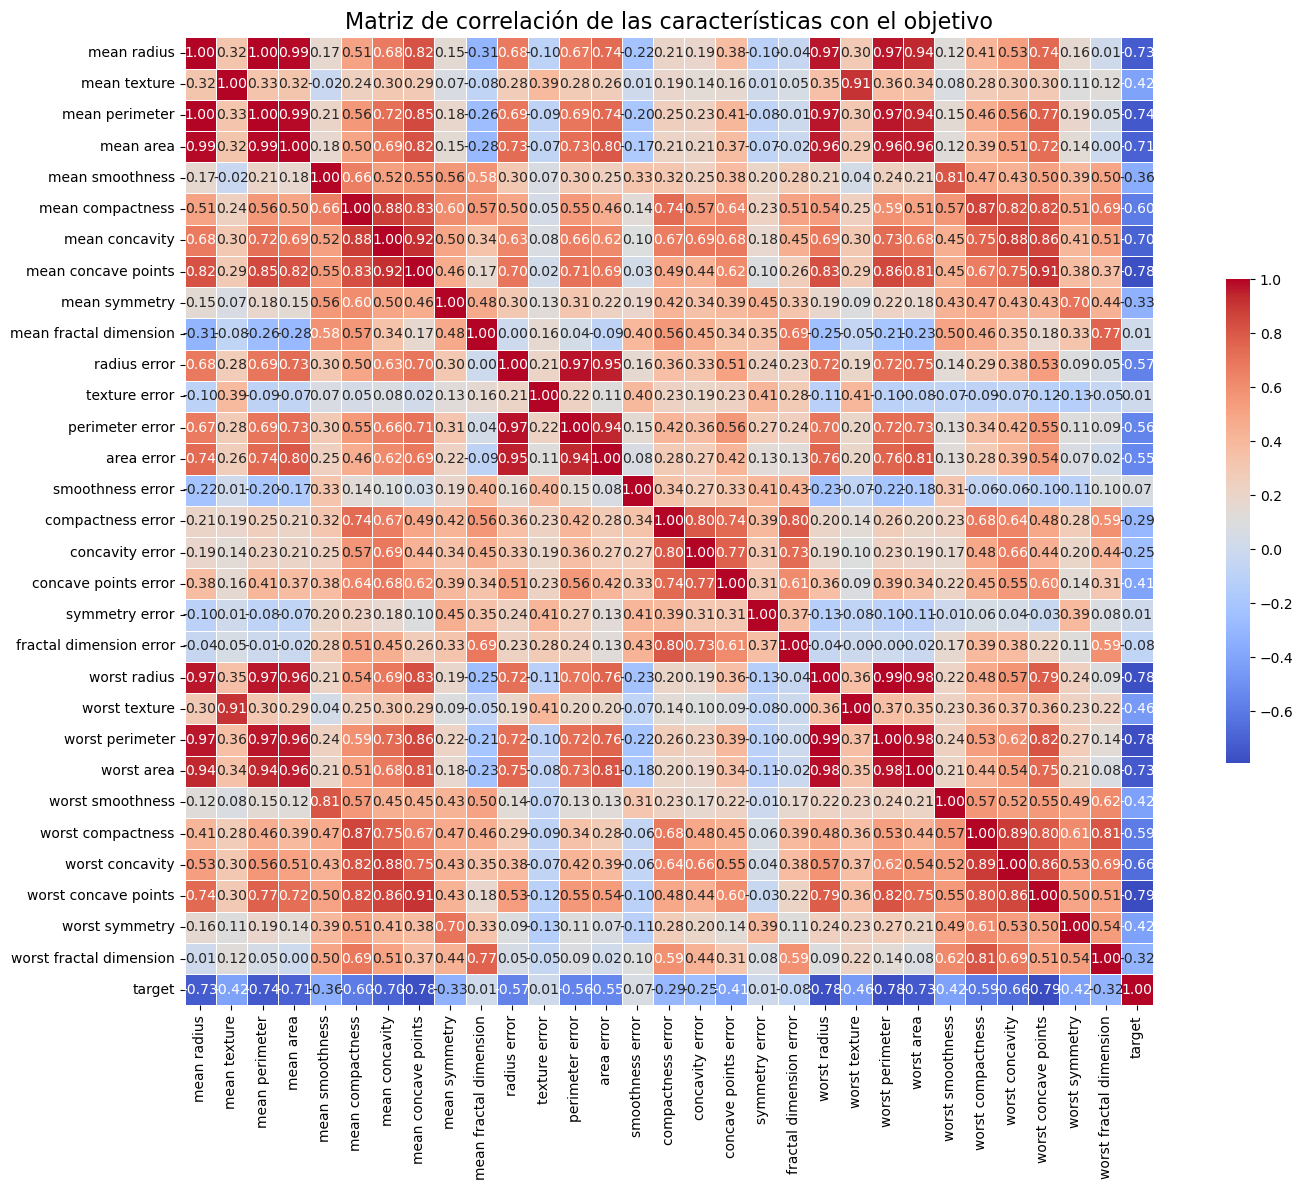

In [34]:
# Calcular la matriz de correlación
correlation_matrix = cancer_df.corr()

# Configurar el tamaño del gráfico
plt.figure(figsize=(16, 12))

# Dibujar el mapa de calor
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, linewidths=0.5, cbar_kws={"shrink": .5})

# Título
plt.title("Matriz de correlación de las características con el objetivo", fontsize=16)

# Mostrar la gráfica
plt.tight_layout()
plt.show()

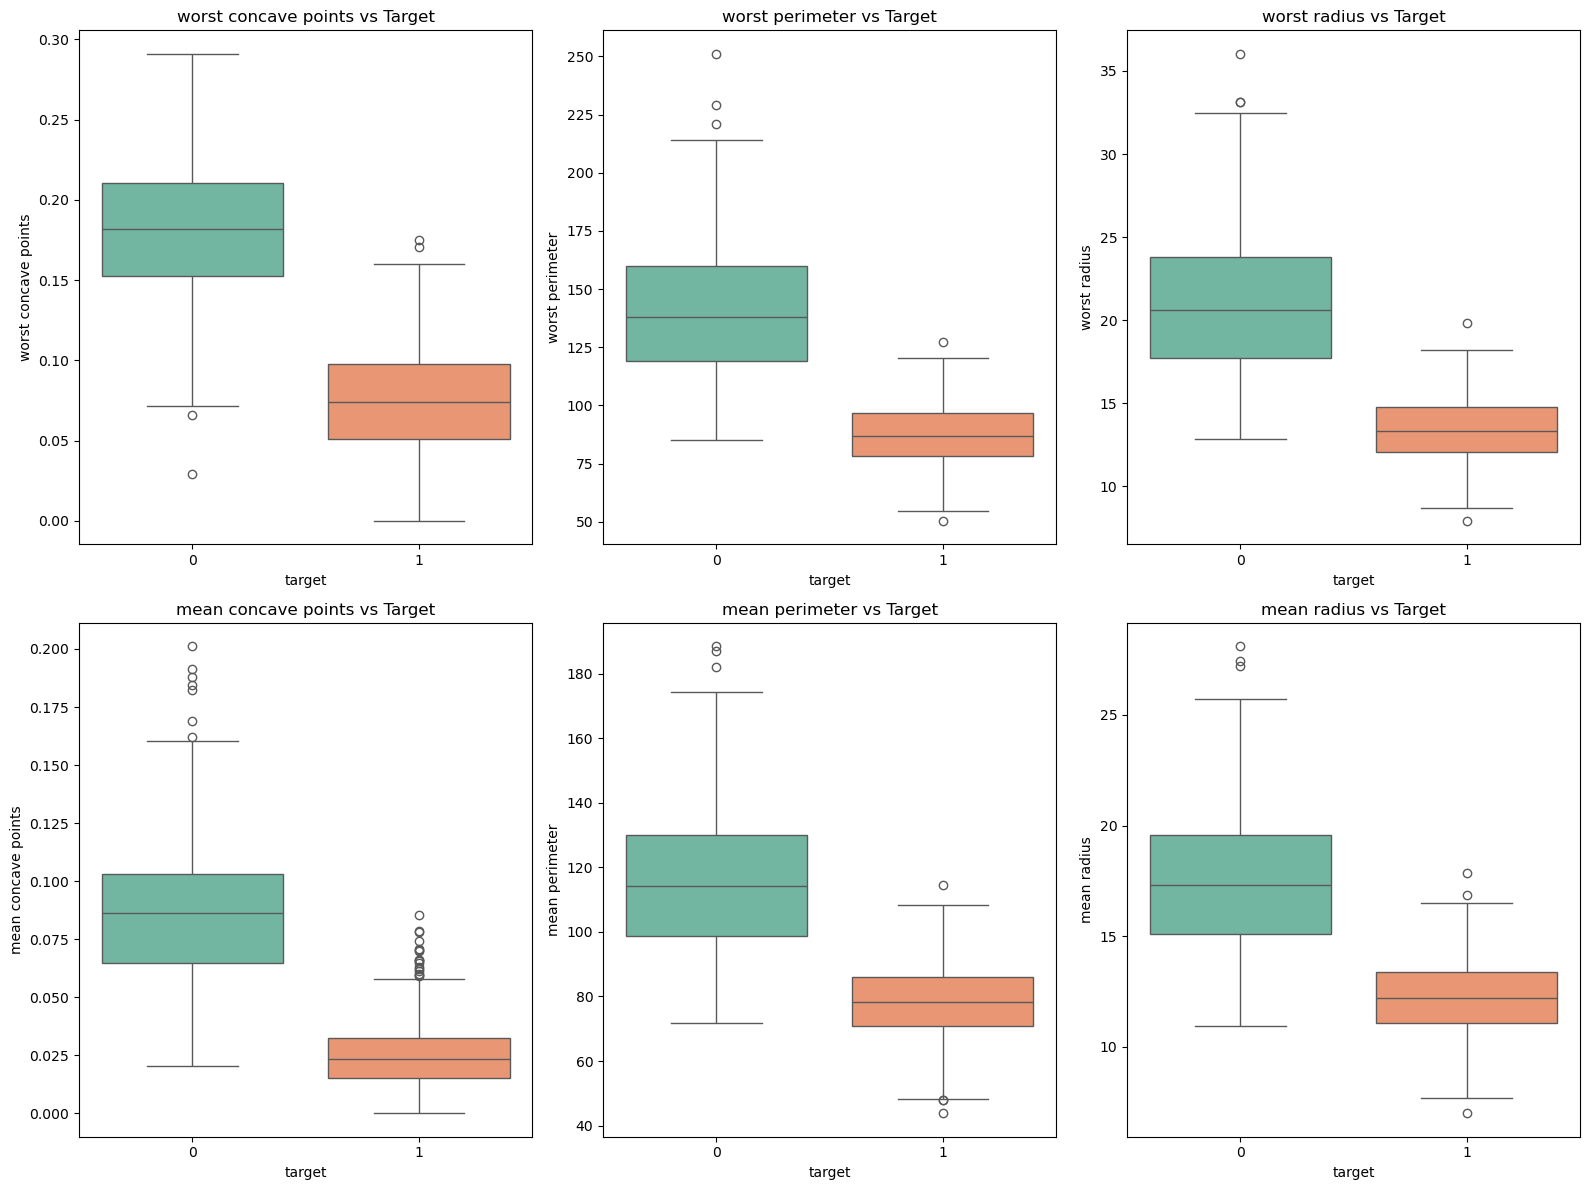

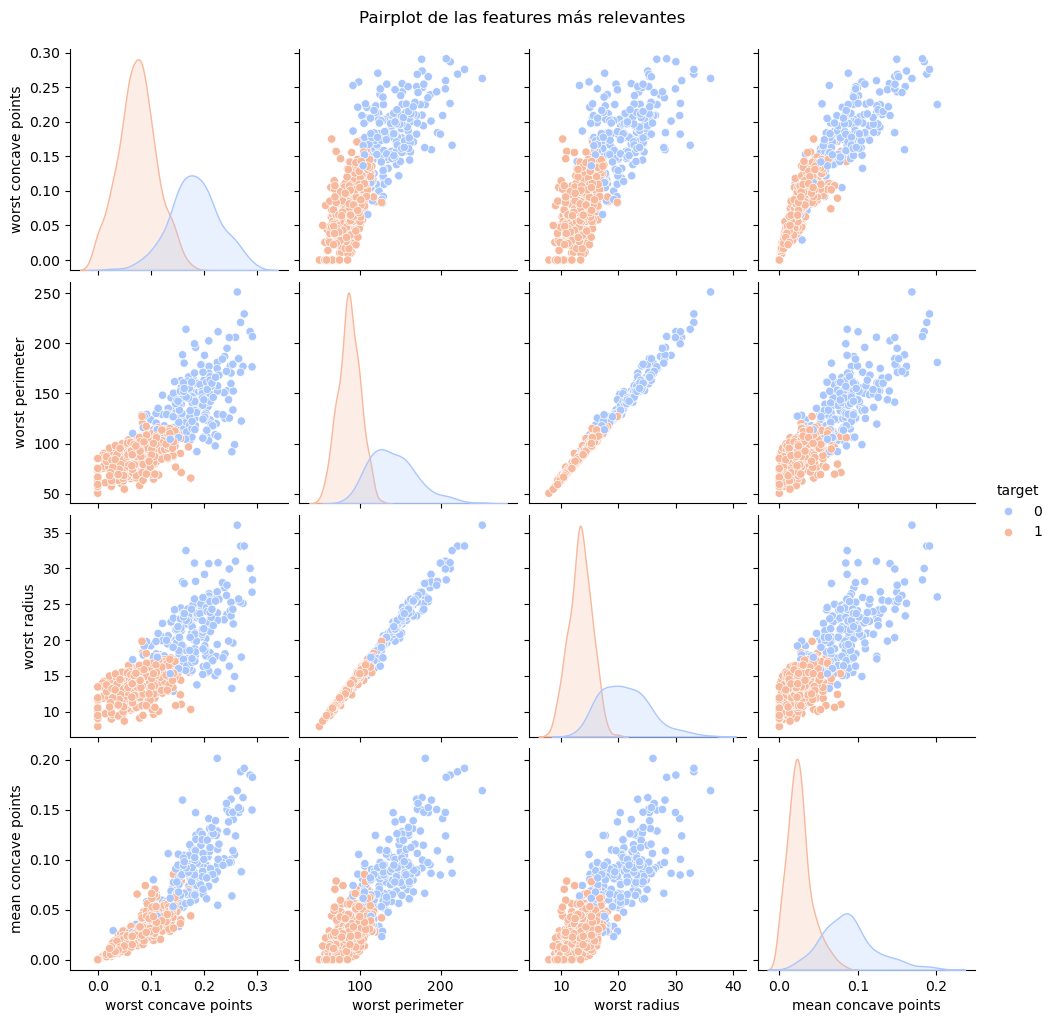

In [35]:
top_features = [
    'worst concave points',
    'worst perimeter',
    'worst radius',
    'mean concave points',
    'mean perimeter',
    'mean radius'
]

plt.figure(figsize=(16, 12))
for i, feature in enumerate(top_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='target', y=feature, data=cancer_df, palette='Set2')
    plt.title(f'{feature} vs Target')
plt.tight_layout()
plt.show()

sns.pairplot(
    cancer_df,
    vars=top_features[:4],  # limitar para mejor visualización
    hue='target',
    palette='coolwarm',
    diag_kind='kde'
)
plt.suptitle('Pairplot de las features más relevantes', y=1.02)
plt.show()


### **Iteration 3: Data Preprocessing**

Prepare the data for training by scaling the features and splitting the dataset.

- **Step 1**: Import `train_test_split` from scikit-learn.
- **Step 2**: Split the dataset into training and test sets with an 80-20 ratio.
- **Step 3**: Standardize the features using a scaler.

In [38]:
from sklearn.model_selection import train_test_split

y = cancer_df['target']
X= cancer_df.drop(['target'], axis=1)

# Standardize the features
scaler = StandardScaler()
X = scaler.fit_transform(cancer_df)

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### **Iteration 4: Model Building**

Create a simple perceptron model using TensorFlow/Keras.

- **Step 1**: Import the necessary components from TensorFlow/Keras.
- **Step 2**: Build a perceptron model with a single Dense layer. The activation function for the output layer should be 'sigmoid'.
- **Step 3**: Compile the model.

In [4]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Your code goes here ...

2025-05-22 14:49:48.755918: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-05-22 14:49:48.756437: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-22 14:49:48.758760: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-22 14:49:48.764932: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1747921788.775541   23638 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1747921788.77

### **Iteration 5: Model Training**

Train the perceptron model on the training data.

- **Step 1**: Train the model for 50 epochs.
- **Step 2**: Track the loss and accuracy during training.

In [5]:
# Your code goes here ...

### **Iteration 6: Model Evaluation**

Evaluate the performance of your perceptron model on the test data.

- **Step 1**: Use the `evaluate()` function to check the accuracy of the model on the test set.
- **Step 2**: Plot the training and validation accuracy over epochs to visualize the learning process.


In [6]:
# Your code goes here ...

### **Iteration 7: Conclusion and Reflection**

After completing the above steps, reflect on the results and write down your observations:
- How did the perceptron perform on the binary classification task?
- What challenges did you encounter during training, and how did you overcome them?
- How would you modify the model for better performance?

### Reflections

- **Perceptron performance**: 
- **Challenges encountered**: 
- **Improvements for future models**: 